# Lab 3 - Homework



## Ładowanie danych

In [29]:
import polars as pl
import matplotlib.pyplot as plt

DATA_DIR = "data"

# kolumny money-related
MONEY_COLS = [
    "fare_amount",
    "extra",
    "mta_tax",
    "tip_amount",
    "tolls_amount",
    "improvement_surcharge",
    "total_amount",
    "congestion_surcharge",
    "Airport_fee",
]

In [30]:
# konwersja mikrosekund (naprawa błędu z laba)
dfs = []
for month in range(1, 13):
    df = pl.scan_parquet(f"{DATA_DIR}/{month}.parquet").with_columns(
        pl.col("tpep_pickup_datetime").dt.cast_time_unit("us"),
        pl.col("tpep_dropoff_datetime").dt.cast_time_unit("us"),
    )
    dfs.append(df)


In [31]:
# łączenie miesięcy w cały rocznik i optymalizacja typów
df_raw = (
    pl.concat(dfs)
    .drop("store_and_fwd_flag")
    .with_columns(
        pl.col("VendorID").cast(pl.UInt8),
        pl.col("RatecodeID").cast(pl.UInt8),
        pl.col("payment_type").cast(pl.UInt8),
        pl.col("PULocationID").cast(pl.UInt16),
        pl.col("DOLocationID").cast(pl.UInt16),
    )
    .filter(
        pl.col("tpep_pickup_datetime").dt.year() == 2024,
        pl.col("tpep_dropoff_datetime") <= pl.datetime(2025, 1, 1),
    )
)

In [32]:
# Struktura z danymi o strefach taxi
df_zones = pl.scan_csv(f"{DATA_DIR}/taxi_zone_lookup.csv").select(
    pl.col("LocationID").cast(pl.UInt16),
    pl.col("Borough").cast(pl.Categorical),
)

In [33]:
df_raw.collect_schema()

Schema([('VendorID', UInt8),
        ('tpep_pickup_datetime', Datetime(time_unit='us', time_zone=None)),
        ('tpep_dropoff_datetime', Datetime(time_unit='us', time_zone=None)),
        ('passenger_count', Int64),
        ('trip_distance', Float64),
        ('RatecodeID', UInt8),
        ('PULocationID', UInt16),
        ('DOLocationID', UInt16),
        ('payment_type', UInt8),
        ('fare_amount', Float64),
        ('extra', Float64),
        ('mta_tax', Float64),
        ('tip_amount', Float64),
        ('tolls_amount', Float64),
        ('improvement_surcharge', Float64),
        ('total_amount', Float64),
        ('congestion_surcharge', Float64),
        ('Airport_fee', Float64)])

## Czyszczenie danych i filtrowanie

In [34]:
df_clean = (
    df_raw.with_columns(pl.col("passenger_count").fill_null(1))
    .filter(pl.col("passenger_count") > 0)
    .with_columns(pl.col("passenger_count").clip(upper_bound=6).cast(pl.UInt8))
    .filter(pl.col("tpep_dropoff_datetime") - pl.col("tpep_pickup_datetime") <= pl.duration(hours=2))
    .with_columns(pl.col(MONEY_COLS).abs())
    .filter([pl.col(c) <= 1000 for c in MONEY_COLS])
    .filter(
        pl.col("RatecodeID").is_in([1, 2, 3, 4, 5, 6]),
        pl.col("VendorID").is_in([1, 2, 6, 7]),
    )
)

## Transformacje

In [35]:
# Definicja zmiennych helperów
pickup_time = pl.col("tpep_pickup_datetime").dt.time()

is_rush_hour = (pl.col("tpep_pickup_datetime").dt.weekday() <= 5) & (
    pickup_time.is_between(pl.time(6, 30), pl.time(9, 30))
    | pickup_time.is_between(pl.time(15, 30), pl.time(20, 0))
)

In [36]:
# Transformacja
df_transformed = (
    df_clean.with_columns(
        pl.when(pl.col("payment_type") == 1)
        .then(pl.lit("card"))
        .when(pl.col("payment_type") == 2)
        .then(pl.lit("cash"))
        .otherwise(pl.lit("other"))
        .alias("payment_type")
    )
    .join(df_zones.rename({"Borough": "start_borough"}), left_on="PULocationID", right_on="LocationID")
    .join(df_zones.rename({"Borough": "end_borough"}), left_on="DOLocationID", right_on="LocationID")
    .drop("PULocationID", "DOLocationID")
    .with_columns(
        (pl.col("Airport_fee") > 0).alias("is_airport_ride"),
        is_rush_hour.alias("is_rush_hour"),
    )
)

## Ekstrakcja cech

In [37]:
# Lista dzielnic
boroughs = pl.read_csv(f"{DATA_DIR}/taxi_zone_lookup.csv")["Borough"].unique().sort().to_list()
boroughs

['Bronx',
 'Brooklyn',
 'EWR',
 'Manhattan',
 'N/A',
 'Queens',
 'Staten Island',
 'Unknown']

In [38]:
# dummy kolumny
dummies = []
for p in ["card", "cash", "other"]:
    dummies.append((pl.col("payment_type") == p).alias(f"rides_{p}"))

for b in boroughs:
    name = b.lower().replace(" ", "_").replace("/", "_")
    dummies.append((pl.col("start_borough") == b).alias(f"rides_from_{name}"))
    dummies.append((pl.col("end_borough") == b).alias(f"rides_to_{name}"))

In [39]:
# tabela
df_dataset = (
    df_transformed.with_columns(pl.col("tpep_pickup_datetime").dt.date().alias("date"))
    .with_columns(dummies)
    .group_by("date")
    .agg(
        # inty
        pl.len().alias("rides_count"),
        pl.col("is_airport_ride").sum().alias("airport_rides_count"),
        pl.col("is_rush_hour").sum().alias("rush_hour_rides_count"),
        # featursy
        pl.col("fare_amount").mean().alias("fare_amount_mean"),
        pl.col("trip_distance").median().alias("trip_distance_median"),
        pl.col("total_amount").sum().alias("total_amount_sum"),
        pl.col("total_amount").filter(pl.col("payment_type") == "card").sum().alias("total_amount_card"),
        pl.col("total_amount").filter(pl.col("payment_type") == "cash").sum().alias("total_amount_cash"),
        pl.col("total_amount").filter(pl.col("payment_type") == "other").sum().alias("total_amount_other"),
        pl.col("congestion_surcharge").sum().alias("congestion_surcharge_sum"),
        pl.col("passenger_count").sum().cast(pl.UInt32).alias("passengers_count"),
    )
    # czasowe kolumny
    .with_columns(
        pl.col("date").dt.quarter().alias("quarter"),
        pl.col("date").dt.month().alias("month"),
        pl.col("date").dt.day().alias("day_of_month"),
        pl.col("date").dt.weekday().alias("day_of_week"),
        (pl.col("date").dt.weekday() >= 6).alias("is_weekend"),
    )
    .sort("date")
)

In [40]:
# zapis
df_dataset = df_dataset.collect()
df_dataset.write_parquet("dataset.parquet")

## Analiza

In [41]:
df_dataset.shape

(366, 17)

In [42]:
df_dataset.head()

date,rides_count,airport_rides_count,rush_hour_rides_count,fare_amount_mean,trip_distance_median,total_amount_sum,total_amount_card,total_amount_cash,total_amount_other,congestion_surcharge_sum,passengers_count,quarter,month,day_of_month,day_of_week,is_weekend
date,u32,u32,u32,f64,f64,f64,f64,f64,f64,f64,u32,i8,i8,i8,i8,bool
2024-01-01,69541,8352,19360,22.184388,2.09,2.1793e6,1.7389e6,384662.67,55778.86,156123.25,109013,1,1,1,1,false
2024-01-02,71443,9828,30554,21.312124,1.8,2.2095e6,1.7617e6,396334.47,51441.03,160615.0,102927,1,1,2,2,false
2024-01-03,78399,9140,32924,19.968751,1.72,2.2900e6,1.8242e6,416241.57,49554.25,177985.0,109805,1,1,3,3,false
2024-01-04,97896,8270,43112,18.68711,1.73,2.7179e6,2.2134e6,444631.77,59823.2,226627.5,134634,1,1,4,4,false
2024-01-05,97958,7460,40150,18.114238,1.7,2.6451e6,2.1666e6,420694.52,57798.23,227540.0,136260,1,1,5,5,false


In [43]:
df_dataset.describe()

statistic,date,rides_count,airport_rides_count,rush_hour_rides_count,fare_amount_mean,trip_distance_median,total_amount_sum,total_amount_card,total_amount_cash,total_amount_other,congestion_surcharge_sum,passengers_count,quarter,month,day_of_month,day_of_week,is_weekend
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""","""366""",366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0
"""null_count""","""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""","""2024-07-01 12:00:00""",98867.300546,8977.81694,29516.784153,19.786164,1.703374,2.8672e6,2.4169e6,372223.376667,78109.084344,230200.254153,133727.789617,2.505464,6.513661,15.756831,3.986339,0.284153
"""std""",null,15192.844685,1716.370323,19423.582497,1.206237,0.102174,453452.472008,420941.772074,36187.455655,17245.96652,37863.324471,18672.609688,1.119551,3.455958,8.823592,2.006108,null
"""min""","""2024-01-01""",46930.0,3355.0,0.0,16.623276,1.5,1.3081e6,978705.28,240633.43,41303.84,107820.0,73723.0,1.0,1.0,1.0,1.0,0.0
"""25%""","""2024-04-01""",88657.0,7869.0,0.0,18.945217,1.64,2.5439e6,2.1289e6,352425.45,65781.9,203501.0,121081.0,2.0,4.0,8.0,2.0,null
"""50%""","""2024-07-02""",99489.0,9018.0,38944.0,19.751554,1.69,2.8746e6,2.4310e6,375876.77,79216.96,232817.5,132914.0,3.0,7.0,16.0,4.0,null
"""75%""","""2024-10-01""",109654.0,10144.0,44107.0,20.549493,1.75,3.1880e6,2.6994e6,398461.95,90101.99,256939.5,145601.0,4.0,10.0,23.0,6.0,null
"""max""","""2024-12-31""",140079.0,14903.0,55965.0,24.370708,2.2,4.4077e6,3.8619e6,449947.01,123886.72,330475.0,198656.0,4.0,12.0,31.0,7.0,1.0


In [44]:
df_dataset.schema

Schema([('date', Date),
        ('rides_count', UInt32),
        ('airport_rides_count', UInt32),
        ('rush_hour_rides_count', UInt32),
        ('fare_amount_mean', Float64),
        ('trip_distance_median', Float64),
        ('total_amount_sum', Float64),
        ('total_amount_card', Float64),
        ('total_amount_cash', Float64),
        ('total_amount_other', Float64),
        ('congestion_surcharge_sum', Float64),
        ('passengers_count', UInt32),
        ('quarter', Int8),
        ('month', Int8),
        ('day_of_month', Int8),
        ('day_of_week', Int8),
        ('is_weekend', Boolean)])

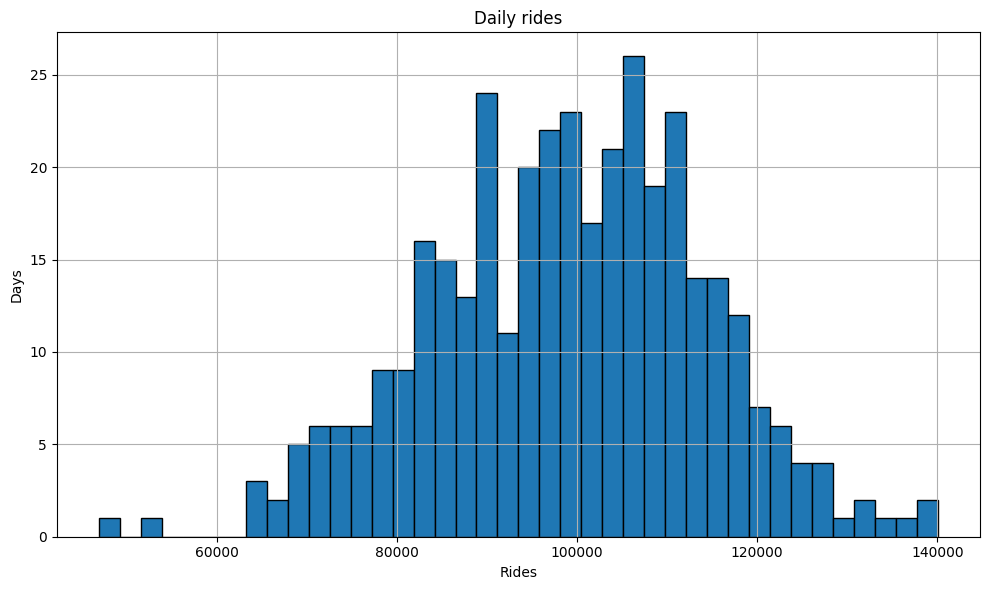

In [45]:
df_plot = df_dataset.select("date", "rides_count").to_pandas()

ax = df_plot["rides_count"].plot.hist(bins=40, figsize=(10, 6), edgecolor="black")
ax.set_title("Daily rides")
ax.set_xlabel("Rides")
ax.set_ylabel("Days")
plt.grid(True)
plt.tight_layout()
plt.show()